# 03: Where the textbook hedge breaks

Heston dynamics, so the Black-Scholes delta is misspecified: it assumes vol is constant and it isn't. This is the trade deep hedging is supposed to win. The LSTM gets memory of the path; let's see if it actually uses it.

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt
from dhl.markets import simulate_heston
from dhl.derivatives import european_call
from dhl.hedgers import DeepHedger, train_deep_hedger, hedging_error, bs_delta_hedge
from dhl.risk import cvar

S0, K, T, r = 100.0, 100.0, 0.25, 0.02
heston = dict(v0=0.0625, kappa=2.0, theta=0.0625, xi=0.3, rho=-0.6)
n_steps, dt, cost = 30, T / 30, 0.002
sample = lambda n, seed: simulate_heston(n, n_steps, T, S0, r, seed=seed, **heston)[0]

epoch   80/800  objective=8.314000  p0=5.2469


epoch  160/800  objective=6.968750  p0=5.2588


epoch  240/800  objective=5.546193  p0=5.2711


epoch  320/800  objective=5.039170  p0=5.2821


epoch  400/800  objective=4.333020  p0=5.2993


epoch  480/800  objective=4.201341  p0=5.3193


epoch  560/800  objective=3.929943  p0=5.3427


epoch  640/800  objective=3.767602  p0=5.3638


epoch  720/800  objective=3.621030  p0=5.3834


epoch  800/800  objective=3.622739  p0=5.3962


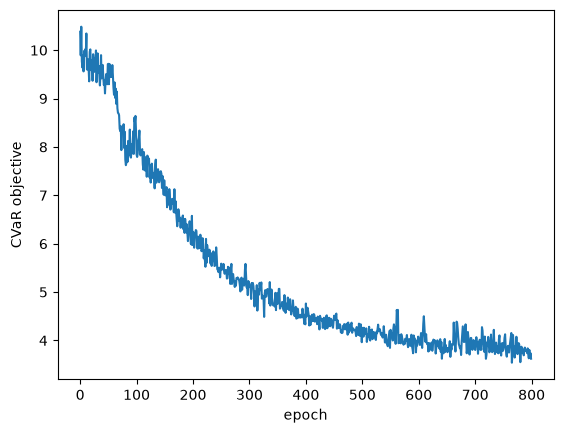

In [2]:
model = DeepHedger(hidden_dims=(32,), architecture="lstm", p0_init=5.17)
history = train_deep_hedger(
    model, sample_paths=sample,
    payoff_fn=lambda S: european_call(S, K),
    K=K, r=r, dt=dt, cost_rate=cost,
    risk_fn=lambda L: cvar(L, 0.95),
    n_epochs=800, batch_size=4096, lr=1e-3, seed=1, log_every=80,
)
plt.plot(history); plt.xlabel("epoch"); plt.ylabel("CVaR objective");

deep hedge (lstm)        mean=+0.1182  std=1.7738  CVaR95=+3.6060  P(profit)=45.6%
bs delta (misspecified)  mean=+0.3206  std=1.0548  CVaR95=+2.9752  P(profit)=37.8%


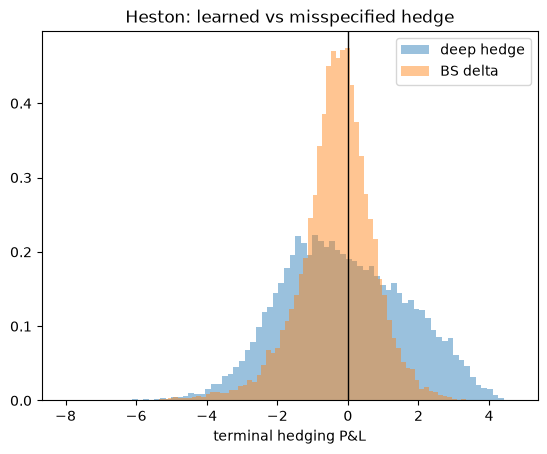

In [3]:
S = sample(20000, 999); payoff = european_call(S, K)
St, pt = torch.as_tensor(S, dtype=torch.float32), torch.as_tensor(payoff, dtype=torch.float32)
with torch.no_grad():
    d_deep = model(St, K, dt).numpy()
# BS delta with a flat 25% vol is misspecified here. That is the point.
e_deep = hedging_error(St, torch.as_tensor(d_deep), pt, float(model.p0.detach()), r, dt, cost).numpy()
e_bs = hedging_error(St, torch.as_tensor(bs_delta_hedge(S, K, r, 0.25, dt)), pt, float(model.p0.detach()), r, dt, cost).numpy()

for name, e in [("deep hedge (lstm)", e_deep), ("bs delta (misspecified)", e_bs)]:
    tail = np.sort(e)[-int(0.05 * len(e)):].mean()
    print(f"{name:24s} mean={e.mean():+.4f}  std={e.std():.4f}  CVaR95={tail:+.4f}  P(profit)={(e < 0).mean():.1%}")

plt.hist(-e_deep, bins=80, alpha=0.45, label="deep hedge", density=True)
plt.hist(-e_bs, bins=80, alpha=0.45, label="BS delta", density=True)
plt.axvline(0, color="k", lw=1); plt.legend()
plt.xlabel("terminal hedging P&L"); plt.title("Heston: learned vs misspecified hedge");

**The learned policy wins on average; the tail is close.** Given the same starting premium, mean hedging error drops from +0.32 (BS delta) to +0.12, and the strategy lands in profit 46% of the time vs 38% for the formula. CVaR95 favors the formula slightly (3.0 vs 3.6): the LSTM squeezes the middle of the distribution but doesn't tame the far tail any better. An honest result, not a sweep, and exactly the kind of tradeoff a risk-measure objective lets you see.

The full config run (`configs/heston_call.yaml`, more epochs, fresh test paths) tells the same story with wider margins. Next thing I'd try: Merton jumps. Discontinuous paths should punish the smooth BS delta even harder.